# Общие примеры — мощность, MDE и доверительные интервалы

Это **обзорный ноутбук**; чтобы работать с темой отдельно, удобнее открывать [`power_mde.ipynb`](./power_mde.ipynb) или [`confidence_intervals.ipynb`](./confidence_intervals.ipynb).

Ниже два независимых блока ввода данных. Меняй только числа под заголовком **«ВВОД ДАННЫХ»** и нажимай `Run All`. **Графики включены по умолчанию**, в Jupyter / Colab показываются прямо под ячейками.

Область применения: одна биномиальная доля (одна выборка), не двухвыборочный A/B-тест.

In [1]:
# Служебная ячейка. Ничего менять не нужно.
from power_mde import (binomial_power, binomial_mde, required_sample_size,
                       critical_value_right, plot_power_vs_sample_size,
                       plot_power_vs_effect, plot_binomial_distributions)
from confidence_intervals import (ci_by_inversion, ci_wilson, plot_confidence_intervals)
import matplotlib.pyplot as plt

## 1. ВВОД ДАННЫХ — мощность, MDE и необходимое число наблюдений

Вписывай свои числа **справа от `=`**. Эти значения используются в первых трёх расчётах.

| Поле | Что означает |
|---|---|
| `PLAN_N` | Число независимых испытаний (например, доставок) |
| `PLAN_P0` | Вероятность успеха в `H0` (50% → `0.50`) |
| `PLAN_P_ALT` | Предполагаемая реальная вероятность успеха (60% → `0.60`) |
| `PLAN_ALPHA` | Риск ошибки I рода (обычно `0.05`) |
| `PLAN_TARGET_POWER` | Требуемая мощность (обычно `0.80`) |
| `PLAN_DESIRED_EFFECT` | Желаемый прирост для расчёта размера выборки (+10 п.п. → `0.10`) |

In [2]:
# ======== ВВОД ДАННЫХ — МЕНЯЙ ЭТИ ЧИСЛА ========
PLAN_N = 30                    # Сколько независимых наблюдений уже можем собрать
PLAN_P0 = 0.50                # Вероятность успеха при H0: 50%
PLAN_P_ALT = 0.60             # Предполагаемая вероятность при H1: 60%
PLAN_ALPHA = 0.05             # Уровень значимости: 5%
PLAN_TARGET_POWER = 0.80      # Желаемая мощность: 80%
PLAN_DESIRED_EFFECT = 0.10    # Желаемый MDE для подбора n: +10 процентных пунктов
# =================================================

### Результат 1 — статистическая мощность

**Вопрос:** если реальная конверсия равна `PLAN_P_ALT`, какова вероятность обнаружить её превышение над `PLAN_P0`? `beta = 1 - мощность` — риск пропустить реальное улучшение.

In [3]:
critical = critical_value_right(PLAN_N, PLAN_P0, PLAN_ALPHA)
power = binomial_power(PLAN_N, PLAN_P0, PLAN_P_ALT, PLAN_ALPHA)
print("МОЩНОСТЬ КРИТЕРИЯ")
print(f"H0: p = {PLAN_P0:.1%}    H1: p > {PLAN_P0:.1%}")
print(f"Объем выборки: {PLAN_N}; ожидаемая реальная доля: {PLAN_P_ALT:.1%}")
print(f"Критическая область: число успехов >= {critical}")
print(f"Мощность: {power:.2%}")
print(f"Вероятность пропустить эффект (beta): {1-power:.2%}")

МОЩНОСТЬ КРИТЕРИЯ
H0: p = 50.0%    H1: p > 50.0%
Объем выборки: 30; ожидаемая реальная доля: 60.0%
Критическая область: число успехов >= 20
Мощность: 29.15%
Вероятность пропустить эффект (beta): 70.85%


### Результат 2 — MDE при заданном числе наблюдений

**Вопрос:** какой **минимальный абсолютный прирост** относительно `PLAN_P0` удастся обнаружить при `PLAN_N`, `PLAN_ALPHA` и целевой мощности `PLAN_TARGET_POWER`?

In [4]:
mde_actual = binomial_mde(PLAN_N, PLAN_P0, PLAN_ALPHA, PLAN_TARGET_POWER)
print("MDE — МИНИМАЛЬНЫЙ ДЕТЕКТИРУЕМЫЙ ЭФФЕКТ")
print(f"MDE: +{mde_actual * 100:.2f} п.п.")
print(f"От {PLAN_P0:.2%} до {(PLAN_P0 + mde_actual):.2%}")
print(f"При n={PLAN_N}, alpha={PLAN_ALPHA:.2%}, желаемой мощности={PLAN_TARGET_POWER:.0%}")

MDE — МИНИМАЛЬНЫЙ ДЕТЕКТИРУЕМЫЙ ЭФФЕКТ
MDE: +21.84 п.п.
От 50.00% до 71.84%
При n=30, alpha=5.00%, желаемой мощности=80%


### Результат 3 — необходимый размер выборки

**Вопрос:** сколько наблюдений требуется, чтобы обнаружить **заданный** абсолютный прирост `PLAN_DESIRED_EFFECT` с мощностью `PLAN_TARGET_POWER`? Важно: речь о **числе наблюдений в одной выборке**.

In [5]:
needed_n = required_sample_size(
    p0=PLAN_P0,
    mde=PLAN_DESIRED_EFFECT,
    alpha=PLAN_ALPHA,
    target_power=PLAN_TARGET_POWER,
)
final_power = binomial_power(needed_n, PLAN_P0, PLAN_P0 + PLAN_DESIRED_EFFECT, PLAN_ALPHA)
print("МИНИМАЛЬНЫЙ РАЗМЕР ВЫБОРКИ")
print(f"Эффект для обнаружения: +{PLAN_DESIRED_EFFECT*100:.2f} п.п.")
print(f"Нужно как минимум: {needed_n} независимых наблюдений")
print(f"Фактическая мощность при n={needed_n}: {final_power:.2%}")

МИНИМАЛЬНЫЙ РАЗМЕР ВЫБОРКИ
Эффект для обнаружения: +10.00 п.п.
Нужно как минимум: 158 независимых наблюдений
Фактическая мощность при n=158: 80.57%


## 2. ВВОД ДАННЫХ — доверительные интервалы

Здесь используются **реально наблюдённые** результаты.

| Поле | Что означает |
|---|---|
| `CI_N` | Всего наблюдений |
| `CI_SUCCESSES` | Сколько из них успешных |
| `CI_ALPHA` | `0.05` для 95%-го интервала |
| `CI_GRID_STEP` | Шаг перебора для метода из лекции (`0.001`) |

Две реализации: **инверсия критерия по сетке** (точный биномиальный критерий, но границы на сетке) и **Уилсон** (быстрый приближённый метод).

In [6]:
# ======== ВВОД ДАННЫХ — МЕНЯЙ ЭТИ ЧИСЛА ========
CI_N = 30                     # Количество наблюдений (доставок)
CI_SUCCESSES = 19             # Количество успешных наблюдений
CI_ALPHA = 0.05               # Уровень значимости, 0.05 => 95%-й интервал
CI_GRID_STEP = 0.001          # Шаг перебора для первого метода: 0.1 п.п.
# =================================================

### Результат 4 — двусторонние доверительные интервалы **двумя способами**

**Вопрос:** в каком интервале может находиться истинная конверсия? Интервалы не нужно интерпретировать как «вероятность 95%, что параметр лежит здесь».

In [7]:
# Метод из лекции: инверсия двустороннего биномиального критерия.
ci_grid = ci_by_inversion(
    successes=CI_SUCCESSES, n=CI_N, alpha=CI_ALPHA,
    grid_step=CI_GRID_STEP, side="two-sided",
)
# Метод Уилсона: быстрый приближенный доверительный интервал.
ci_wilson_result = ci_wilson(
    successes=CI_SUCCESSES, n=CI_N, alpha=CI_ALPHA, side="two-sided",
)
print(f"НАБЛЮДАЕМАЯ ДОЛЯ УСПЕХОВ: {CI_SUCCESSES}/{CI_N} = {CI_SUCCESSES/CI_N:.2%}")
print(f"ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ (уровень {1-CI_ALPHA:.0%})")
print(f"Перебор гипотез: от {ci_grid[0]:.2%} до {ci_grid[1]:.2%}")
print(f"Интервал Уилсона: от {ci_wilson_result[0]:.2%} до {ci_wilson_result[1]:.2%}")

НАБЛЮДАЕМАЯ ДОЛЯ УСПЕХОВ: 19/30 = 63.33%
ДОВЕРИТЕЛЬНЫЕ ИНТЕРВАЛЫ (уровень 95%)
Перебор гипотез: от 43.90% до 80.00%
Интервал Уилсона: от 45.51% до 78.13%


### Результат 5 — односторонняя нижняя доверительная граница

**Вопрос:** какую **нижнюю границу** конверсии можно обосновать данными? В этом режиме функции возвращают `(нижняя_граница, 1.0)`. Верхнее `1.0` означает, что верхнюю границу мы не оцениваем.

In [8]:
ci_grid_lower = ci_by_inversion(CI_SUCCESSES, CI_N, CI_ALPHA, CI_GRID_STEP, side="lower")
ci_wilson_lower = ci_wilson(CI_SUCCESSES, CI_N, CI_ALPHA, side="lower")
print(f"ОДНОСТОРОННЯЯ НИЖНЯЯ ГРАНИЦА (уровень {1-CI_ALPHA:.0%})")
print(f"Перебор гипотез: p >= {ci_grid_lower[0]:.2%}")
print(f"Интервал Уилсона: p >= {ci_wilson_lower[0]:.2%}")

ОДНОСТОРОННЯЯ НИЖНЯЯ ГРАНИЦА (уровень 95%)
Перебор гипотез: p >= 46.70%
Интервал Уилсона: p >= 48.33%


## 3. ГРАФИКИ (необязательно)

По умолчанию `SHOW_PLOTS=True`: три графика отображаются в выводе ниже. Для отключения установи `False`.

- Как мощность зависит от размера выборки;
- Как мощность зависит от величины эффекта с отметкой MDE;
- Сравнение доверительных интервалов перебором и по Уилсону.

**Дополнительные графики** (критическая область и фактическое покрытие интервала Уилсона) есть в тематических ноутбуках `power_mde.ipynb` и `confidence_intervals.ipynb`.

In [9]:
# ======== РЕЖИМ ГРАФИКОВ ========
SHOW_PLOTS = True             # True — графики видны прямо здесь; False — не строить
# =================================

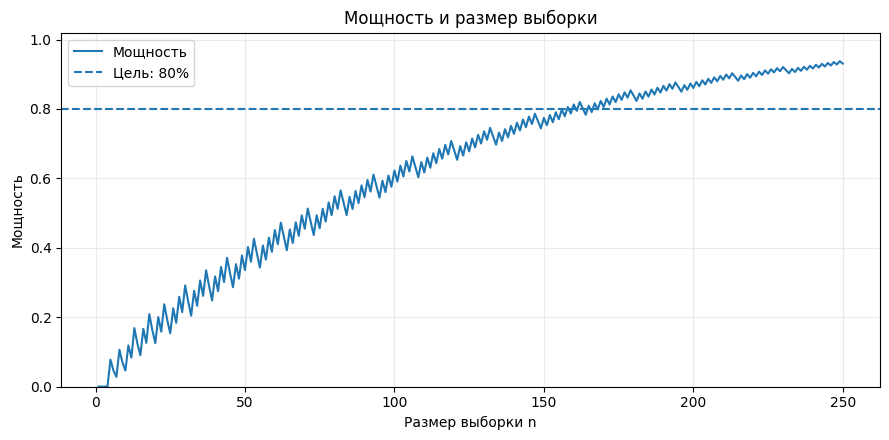

In [10]:
if SHOW_PLOTS:
    fig = plot_power_vs_sample_size(PLAN_P0, PLAN_P_ALT, PLAN_ALPHA,
                                    PLAN_TARGET_POWER, max_n=min(max(needed_n+50, 250), 2000))
    plt.show()

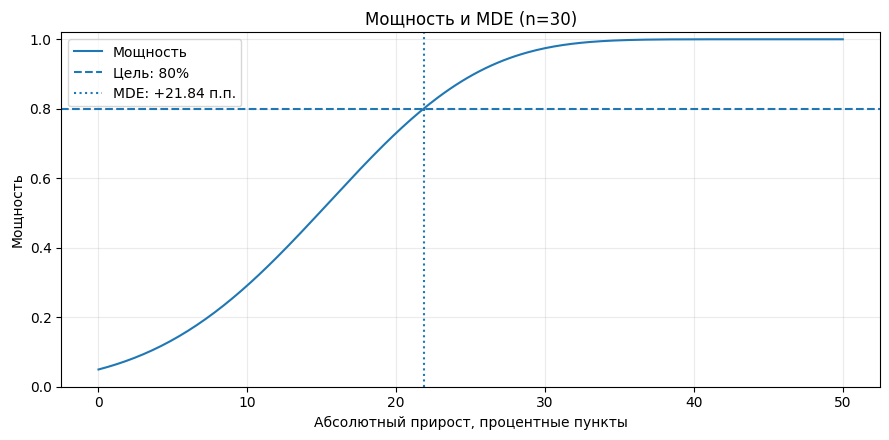

In [11]:
if SHOW_PLOTS:
    fig = plot_power_vs_effect(PLAN_N, PLAN_P0, PLAN_ALPHA, PLAN_TARGET_POWER)
    plt.show()

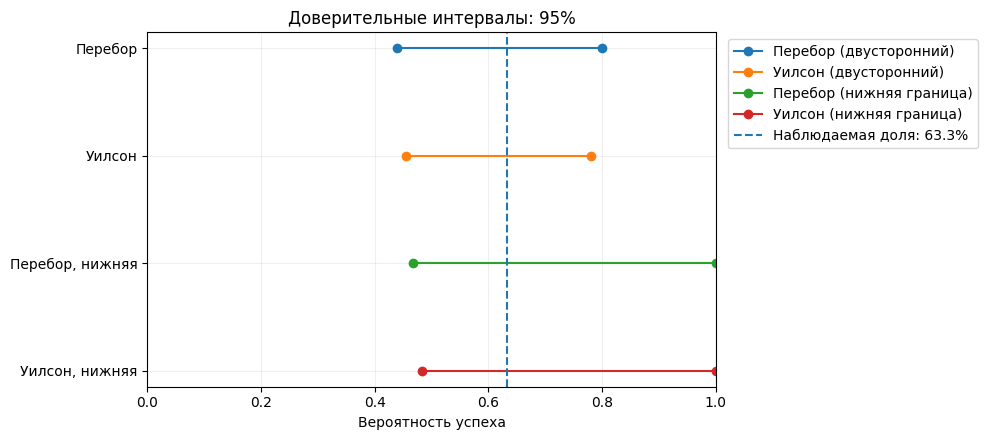

In [12]:
if SHOW_PLOTS:
    fig = plot_confidence_intervals(CI_SUCCESSES, CI_N, CI_ALPHA, CI_GRID_STEP)
    plt.show()

### Что считать дальше?

Чтобы проверять **разницу конверсий двух независимых групп A/B**, нужно отдельное расширение. Этот ноутбук считает только **одну вероятность успеха**. Дополнительные теоретические пояснения и исходник лекции — в [`README.md`](./README.md).